# Curvas de validación y estabilidad de coeficientes (7.3 y 7.4)

Dueño: Julián. Solo análisis y figuras: la lógica reutilizable va en `src/`.
Antes de cada commit: Kernel → Restart & Run All.

**Qué hace este cuaderno.** Para Ridge, Lasso y KNN corre la misma búsqueda de hiperparámetros que `scripts/entrenar.py` (mismo Pipeline, misma validación cruzada por mes, mismo scorer) y responde tres preguntas:

1. ¿Qué valor del hiperparámetro tiene menor error de validación y qué tan estable es esa elección entre folds?
2. ¿El modelo subajusta o sobreajusta? (brecha entre el error de entrenamiento y el de validación)
3. ¿La regularización estabiliza los coeficientes frente a la MLR completa?

**Solo entrenamiento** (febrero de 2019 a julio de 2025), escenario central. La prueba no se abre en esta entrega. Las búsquedas son deterministas (misma base, mismos folds), así que deben coincidir con `results/tablas/cv_resultados.csv` cuando exista: la última sección lo comprueba.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV

from src.config import OBJETIVO, RUTA_TABLAS
from src.datos.cargar import cargar_entrenamiento
from src.evaluacion.interpretacion import coeficientes_por_fold, estabilidad
from src.evaluacion.particion import CVTemporalPorMes
from src.evaluacion.validar import scorer_mape_nacional
from src.figuras import aplicar_estilo, guardar_figura
from src.modelos.candidatos import construir_candidato

aplicar_estilo()
RUTA_TABLAS.mkdir(parents=True, exist_ok=True)

df = cargar_entrenamiento("central")
cv = CVTemporalPorMes()
print(f"{len(df):,} filas, {df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}")

4,368 filas, 2019-02 a 2025-07


## 1. Búsqueda de hiperparámetros

`return_train_score=True` guarda, además del error de validación de cada fold, el error sobre los meses con que se entrenó ese fold. Sin él no hay curva de entrenamiento.

In [2]:
MODELOS = ["ridge", "lasso", "knn"]
busquedas = {}
for nombre in MODELOS:
    pipe, rejilla = construir_candidato(nombre)
    busquedas[nombre] = GridSearchCV(
        pipe, rejilla, cv=cv, scoring=scorer_mape_nacional,
        return_train_score=True, n_jobs=-1,
    ).fit(df, df[OBJETIVO])
    print(f"{nombre:6} → {busquedas[nombre].best_params_}")

ridge  → {'regressor__modelo__alpha': np.float64(1000.0)}


lasso  → {'regressor__modelo__alpha': np.float64(0.03162277660168379)}


knn    → {'regressor__modelo__n_neighbors': 3, 'regressor__modelo__weights': 'uniform'}


## 2. Tabla de las curvas

- `cv_results_` trae el puntaje de cada fold en `split{k}_test_score` (validación) y `split{k}_train_score` (entrenamiento).
- El scorer devuelve **−MAPE**, porque scikit-learn siempre maximiza: se voltea el signo para trabajar con el MAPE en %.
- La desviación entre folds se calcula con `ddof=1`, igual que `estabilidad()`, para que todas las desviaciones del informe sean comparables (el `std_test_score` de scikit-learn usa `ddof=0`).

In [3]:
def tabla_curva(nombre, busqueda):
    r = busqueda.cv_results_
    k = cv.get_n_splits()
    valida = -np.column_stack([r[f"split{i}_test_score"] for i in range(k)])
    entrena = -np.column_stack([r[f"split{i}_train_score"] for i in range(k)])
    # Nombre corto del hiperparámetro: 'regressor__modelo__alpha' -> 'alpha'
    params = pd.DataFrame(list(r["params"]))
    params.columns = [c.split("__")[-1] for c in params.columns]
    return params.assign(
        modelo=nombre,
        mape_valida=valida.mean(axis=1),
        desv_valida=valida.std(axis=1, ddof=1),
        mape_entrena=entrena.mean(axis=1),
        **{f"valida_fold{i + 1}": valida[:, i] for i in range(k)},
    )


curvas = {n: tabla_curva(n, b) for n, b in busquedas.items()}
pd.concat(curvas.values(), ignore_index=True).to_csv(
    RUTA_TABLAS / "curvas_validacion.csv", index=False, float_format="%.4f"
)
curvas["ridge"][["alpha", "mape_valida", "desv_valida", "mape_entrena"]].round(2)

,alpha,mape_valida,desv_valida,mape_entrena
0,0.00,14.80,6.52,12.79
1,0.00,14.80,6.52,12.79
2,0.01,14.80,6.52,12.79
3,0.03,14.80,6.52,12.79
4,0.10,14.79,6.53,12.79
5,0.32,14.79,6.53,12.79
6,1.00,14.76,6.55,12.77
7,3.16,14.67,6.59,12.73
8,10.00,14.41,6.61,12.65
9,31.62,13.69,6.38,12.46


In [4]:
curvas["lasso"][["alpha", "mape_valida", "desv_valida", "mape_entrena"]].round(2)

,alpha,mape_valida,desv_valida,mape_entrena
0,0.00,14.75,6.58,12.76
1,0.00,14.63,6.66,12.72
2,0.00,14.45,6.86,12.57
3,0.00,14.15,6.93,12.29
4,0.01,11.71,5.90,12.53
5,0.03,9.40,5.66,14.23
6,0.10,11.16,6.46,14.36
7,0.32,11.70,6.95,14.80
8,1.00,11.70,6.95,14.80
9,3.16,11.70,6.95,14.80


In [5]:
curvas["knn"][["n_neighbors", "weights", "mape_valida", "desv_valida",
                "mape_entrena"]].round(2)

,n_neighbors,weights,mape_valida,desv_valida,mape_entrena
0,1,uniform,16.18,11.19,0.00
1,1,distance,16.18,11.19,0.00
2,2,uniform,9.65,5.88,7.06
3,2,distance,10.35,6.05,0.00
4,3,uniform,9.00,4.54,8.51
5,3,distance,9.35,4.78,0.00
6,5,uniform,10.70,3.50,7.93
7,5,distance,10.69,3.84,0.00
8,10,uniform,12.08,4.63,7.05
9,10,distance,11.95,4.67,0.00


## 3. ¿Qué tan segura es la elección? Mejor valor de cada fold

Para cada fold se mira qué valor del hiperparámetro le dio el menor MAPE de validación. Si los 5 folds eligen valores parecidos, la elección es estable; si cada uno elige algo distinto, el mínimo de la curva promedio es frágil. Es la lectura de estabilidad del curso (media y dispersión entre folds), sin entrenar nada más.

In [6]:
def etiqueta(fila, nombre):
    if nombre == "knn":
        return f"k={int(fila['n_neighbors'])}, {fila['weights']}"
    return f"{fila['alpha']:g}"


filas = []
for nombre, t in curvas.items():
    for i in range(cv.get_n_splits()):
        mejor = t.loc[t[f"valida_fold{i + 1}"].idxmin()]
        filas.append({"modelo": nombre, "fold": i + 1,
                      "mejor_valor": etiqueta(mejor, nombre),
                      "mape_valida": mejor[f"valida_fold{i + 1}"]})
por_fold = pd.DataFrame(filas)
por_fold.to_csv(RUTA_TABLAS / "mejor_hiperparametro_por_fold.csv", index=False,
                float_format="%.4f")
por_fold.pivot(index="fold", columns="modelo", values="mejor_valor")

modelo,knn,lasso,ridge
fold,,,
1,"k=2, distance",0.0316228,1000
2,"k=2, uniform",0.0316228,1000
3,"k=3, uniform",0.0316228,3162.28
4,"k=2, uniform",0.001,31.6228
5,"k=5, uniform",0.0316228,3162.28


## 4. Parsimonia: ¿hay un valor más simple casi igual de bueno?

El mínimo de la curva tiene algo de suerte: se eligió mirando esos mismos 5 folds (optimismo de selección). La pregunta es si un valor **más simple** (alpha mayor en Ridge y Lasso, k mayor en KNN) es, con la evidencia que hay, igual de bueno.

**Por qué la comparación es pareada.** La desviación entre folds de la tabla anterior es grande (unos 6 puntos de MAPE) porque hay folds más difíciles que otros **para todos los valores**. Esa dificultad es común y no dice nada sobre qué alpha es mejor. Por eso se compara fold por fold: para cada valor, Δ_k = MAPE_k(valor) − MAPE_k(mínimo) en cada fold k, y se mira la media de Δ y su error estándar (desviación de Δ / √5). Un valor más simple es *equivalente* al mínimo si su Δ medio no supera un error estándar (regla de un error estándar, aplicada a diferencias pareadas). En KNN se compara dentro del tipo de peso elegido. La regla no cambia el modelo sola: si sugiere otro valor, se discute en el punto de control.

In [7]:
FOLDS = [f"valida_fold{i + 1}" for i in range(cv.get_n_splits())]


def comparacion_pareada(t, parametro):
    """Δ fold a fold de cada valor frente al mínimo, su error estándar y si es equivalente."""
    minimo = t.loc[t["mape_valida"].idxmin()]
    delta = t[FOLDS].to_numpy() - minimo[FOLDS].to_numpy(dtype=float)
    salida = t[[parametro, "mape_valida"]].assign(
        delta_medio=delta.mean(axis=1),
        error_estandar=delta.std(axis=1, ddof=1) / np.sqrt(len(FOLDS)),
        folds_peor_que_minimo=(delta > 0).sum(axis=1),
    )
    salida["equivalente"] = salida["delta_medio"] <= salida["error_estandar"]
    return salida


def mas_simple_equivalente(t, parametro):
    p = comparacion_pareada(t, parametro)
    minimo = p.loc[p["mape_valida"].idxmin()]
    eq = p[p["equivalente"]]
    simple = eq.loc[eq[parametro].astype(float).idxmax()]
    return {"minimo": minimo[parametro], "mape_minimo": minimo["mape_valida"],
            "mas_simple_equivalente": simple[parametro],
            "mape_mas_simple": simple["mape_valida"],
            "cambia": simple[parametro] != minimo[parametro]}


peso_knn = busquedas["knn"].best_params_["regressor__modelo__weights"]
knn_peso = curvas["knn"][curvas["knn"]["weights"] == peso_knn]
pd.DataFrame({
    "ridge": mas_simple_equivalente(curvas["ridge"], "alpha"),
    "lasso": mas_simple_equivalente(curvas["lasso"], "alpha"),
    f"knn ({peso_knn})": mas_simple_equivalente(knn_peso, "n_neighbors"),
}).T

,minimo,mape_minimo,mas_simple_equivalente,mape_mas_simple,cambia
ridge,1000.0,9.079339,1000.0,9.079339,False
lasso,0.031623,9.401429,0.031623,9.401429,False
knn (uniform),3,9.002003,3,9.002003,False


In [8]:
# Detalle de Ridge alrededor del mínimo
comparacion_pareada(curvas["ridge"], "alpha").query("100 <= alpha <= 100000").round(2)

,alpha,mape_valida,delta_medio,error_estandar,folds_peor_que_minimo,equivalente
10,100.00,12.09,3.01,2.14,4,False
11,316.23,10.19,1.11,0.80,4,False
12,1000.00,9.08,0.00,0.00,0,True
13,3162.28,9.56,0.48,0.43,3,False
14,10000.00,10.38,1.30,0.73,4,False
15,31622.78,11.03,1.96,0.97,5,False
16,100000.00,11.46,2.38,1.06,5,False


## 5. Figura de curvas de validación

Línea continua: MAPE de validación, con banda de ±1 desviación entre folds. Línea punteada del mismo color: MAPE de entrenamiento. Línea vertical: valor elegido por `GridSearchCV`.

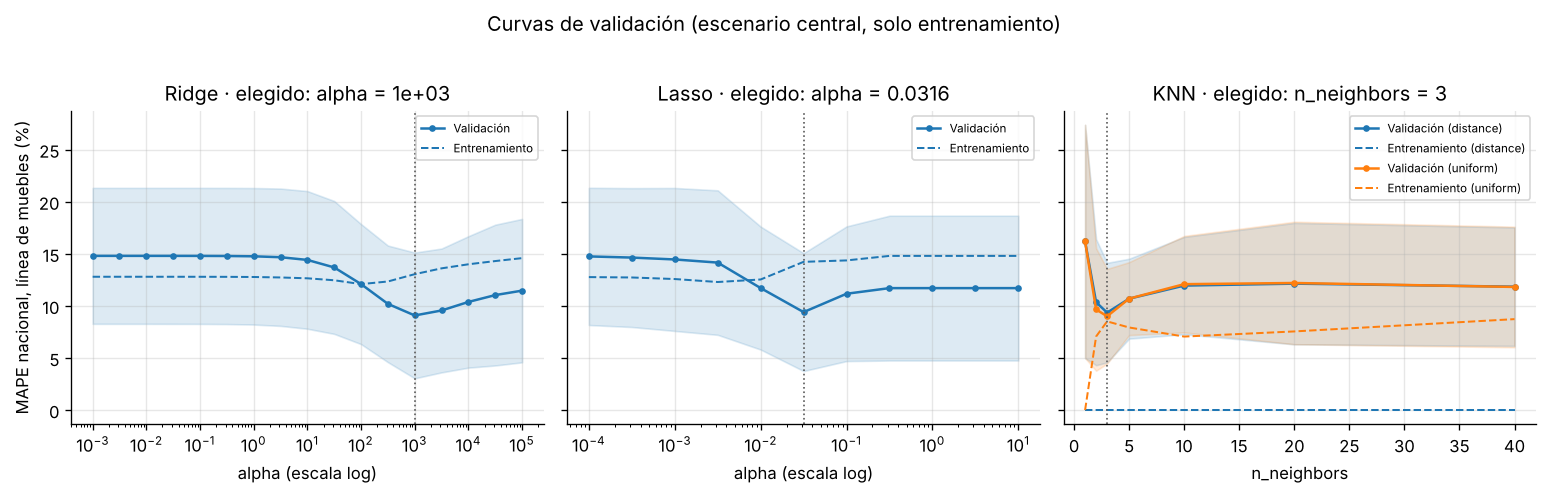

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
paneles = [
    ("ridge", "alpha", None, True, "Ridge"),
    ("lasso", "alpha", None, True, "Lasso"),
    ("knn", "n_neighbors", "weights", False, "KNN"),
]
colores = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for ax, (nombre, param, serie, log, titulo) in zip(ejes, paneles):
    t = curvas[nombre]
    grupos = [(None, t)] if serie is None else list(t.groupby(serie))
    for i, (valor, datos) in enumerate(grupos):
        datos = datos.sort_values(param)
        x = datos[param].astype(float)
        extra = "" if valor is None else f" ({valor})"
        ax.plot(x, datos["mape_valida"], color=colores[i], marker="o", ms=3,
                label=f"Validación{extra}")
        ax.fill_between(x, datos["mape_valida"] - datos["desv_valida"],
                        datos["mape_valida"] + datos["desv_valida"],
                        color=colores[i], alpha=0.15)
        ax.plot(x, datos["mape_entrena"], color=colores[i], ls="--", lw=1.2,
                label=f"Entrenamiento{extra}")
    elegido = busquedas[nombre].best_params_[f"regressor__modelo__{param}"]
    ax.axvline(float(elegido), color="0.35", ls=":", lw=1)
    if log:
        ax.set_xscale("log")
    ax.set_title(f"{titulo} · elegido: {param} = {elegido:.3g}")
    ax.set_xlabel(param + (" (escala log)" if log else ""))
    ax.legend(fontsize=7)
ejes[0].set_ylabel("MAPE nacional, línea de muebles (%)")
fig.suptitle("Curvas de validación (escenario central, solo entrenamiento)", y=1.02)
fig.tight_layout()
guardar_figura(fig, "curvas_validacion")
plt.show()

### Lectura de las curvas

- **Ridge.** El mínimo está en alpha = 1000 (MAPE de validación 9,1 % ± 6,0). Con la rejilla ampliada se ve que es un mínimo de verdad: después la curva vuelve a subir (3162 → 9,6 %; 100.000 → 11,5 %). El valor más simple siguiente, 3162, es peor en 3 de los 5 folds y su Δ medio (0,48) supera su error estándar (0,43): por poco, se queda 1000. Los folds eligen 1000 dos veces, 3162 dos veces y 31,6 una: la elección está entre 1000 y 3162. Con alpha casi cero, Ridge equivale a la MLR completa: 14,8 %.
- **Lasso.** El mínimo está en alpha ≈ 0,032 (9,4 % ± 5,7) y 4 de los 5 folds eligen ese mismo valor. Desde alpha = 0,32 la penalización anula todos los coeficientes, incluidas las dummies, y el error queda plano en 11,7 %.
- **KNN.** El mínimo está en k = 3 con pesos uniformes (9,0 % ± 4,5). Con k = 1 el modelo memoriza: 0 % en entrenamiento y 16,2 % en validación. Con pesos por distancia el MAPE de entrenamiento es 0 para todo k, porque cada fila es su propia vecina a distancia cero: es la señal de sobreajuste que predice la teoría. La elección de k es la menos estable de los tres: los folds eligen k = 2, 2, 3, 2 y 5. KNN usa `algorithm="kd_tree"`: en cerca de un tercio de las filas el k-ésimo vecino empata en distancia con el siguiente, y con el algoritmo por defecto el resultado cambiaba según se corriera en paralelo o no.
- **Entrenamiento por encima de validación.** Con regularización fuerte el MAPE de entrenamiento (≈ 13 %) supera al de validación (≈ 9 %). No es un error: los meses de entrenamiento incluyen abril a agosto de 2020, donde el índice cae a la mitad y el MAPE se dispara, y los de validación (2023 a 2025) no tienen pandemia.
- **Las bandas son anchas** (unos ±6 puntos) porque hay folds más difíciles que otros para todos los modelos. Por eso las comparaciones entre valores y entre modelos se hacen fold por fold, no solo con las medias.

## 6. Estabilidad de los coeficientes

Se ajusta cada modelo lineal en el entrenamiento de cada uno de los 5 folds (los meses de validación no se tocan) y se mira cuánto cambian sus coeficientes. Ridge y Lasso usan el alpha elegido arriba. Solo se muestran los 5 predictores económicos y `covid`: las dummies de mes, departamento y línea son estacionalidad y efectos fijos.

Los coeficientes están **estandarizados**: cambio en log(índice) cuando el predictor sube una desviación estándar, manteniendo fijas las demás variables. Se leen como asociación condicional, no como efecto causal.

In [10]:
pipes = {"mlr_completa": construir_candidato("mlr_completa")[0]}
for nombre in ["ridge", "lasso"]:
    pipe, _ = construir_candidato(nombre)
    pipes[nombre] = pipe.set_params(**busquedas[nombre].best_params_)

tablas = []
for nombre, pipe in pipes.items():
    por_fold_coef = coeficientes_por_fold(pipe, df, cv, OBJETIVO)
    por_fold_coef = por_fold_coef[~por_fold_coef["variable"].str.startswith("cat__")]
    tablas.append(estabilidad(por_fold_coef).assign(modelo=nombre))
estab = pd.concat(tablas, ignore_index=True)
estab["variable"] = estab["variable"].str.split("__").str[-1]
estab.to_csv(RUTA_TABLAS / "estabilidad_coeficientes.csv", index=False,
             float_format="%.5f")
estab.pivot(index="variable", columns="modelo",
            values=["media", "desviacion", "signo_estable"]).round(3)

media                         \
modelo                                   lasso mlr_completa     ridge   
variable                                                                
area_vivienda_m2_rez1                 0.000913     -0.00904  0.021047   
covid                                      0.0     -0.42617 -0.055343   
icc_rez1                                   0.0    -0.061021 -0.007747   
importaciones_muebles_usd_miles_rez1   0.08263     0.029838  0.071045   
inflacion_anual_rez1                  0.023921     0.133301  0.046997   
tasa_consumo_rez1                          0.0    -0.114291 -0.010861   

                                     desviacion                         \
modelo                                    lasso mlr_completa     ridge   
variable                                                                 
area_vivienda_m2_rez1                  0.001146     0.007394  0.001716   
covid                                       0.0     0.016484  0.000647   
icc_rez1                                    0.0     0.011305  0.002645   
importaciones_muebles_usd_miles_rez1   0.006838     0.013196  0.002764   
inflacion_anual_rez1                   0.004555      0.01365  0.002403   
tasa_consumo_rez1                           0.0     0.008113  0.005197   

                                     signo_estable                     
modelo                                       lasso mlr_completa ridge  
variable                                                               
area_vivienda_m2_rez1                         True        False  True  
covid                                         True         True  True  
icc_rez1                                      True         True  True  
importaciones_muebles_usd_miles_rez1          True         True  True  
inflacion_anual_rez1                          True         True  True  
tasa_consumo_rez1                             True         True  True

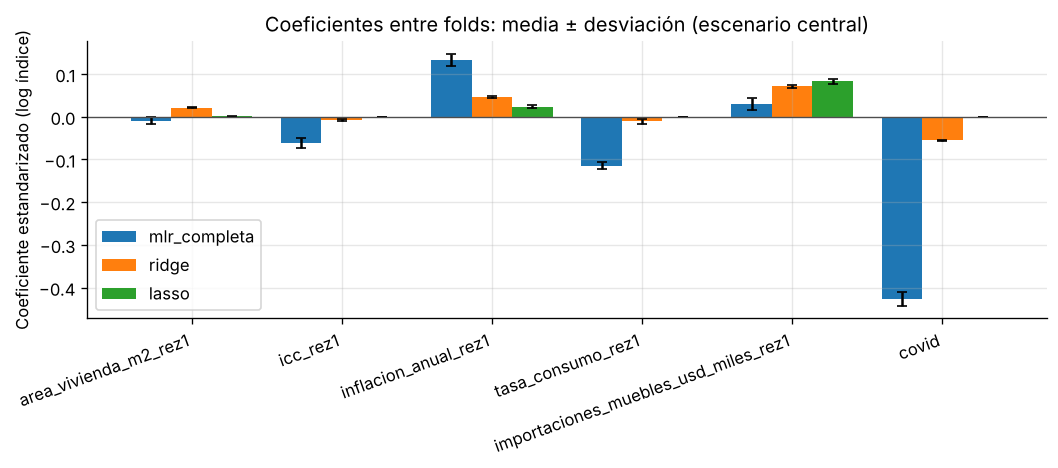

In [11]:
orden = ["mlr_completa", "ridge", "lasso"]
variables = estab["variable"].unique()
fig, ax = plt.subplots(figsize=(9, 4))
ancho = 0.27
for i, nombre in enumerate(orden):
    d = estab[estab["modelo"] == nombre].set_index("variable").loc[variables]
    pos = np.arange(len(variables)) + (i - 1) * ancho
    ax.bar(pos, d["media"], ancho, yerr=d["desviacion"], capsize=3, label=nombre)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(np.arange(len(variables)), variables, rotation=20, ha="right")
ax.set_ylabel("Coeficiente estandarizado (log índice)")
ax.set_title("Coeficientes entre folds: media ± desviación (escenario central)")
ax.legend()
fig.tight_layout()
guardar_figura(fig, "estabilidad_coeficientes")
plt.show()

### Lectura de la estabilidad

Signos esperados por la teoría: importaciones (+), ICC (+), área de vivienda (+), inflación (−), tasa de consumo (−), covid (−).

- **MLR completa.** El área de vivienda **cambia de signo** entre folds y el ICC (−0,061) y la inflación (+0,133) salen con el signo contrario al esperado. Es el síntoma clásico de multicolinealidad: inflación y tasa de consumo se correlacionan 0,85 y la regresión reparte su efecto de forma inestable.
- **Ridge (alpha = 1000).** Ningún coeficiente cambia de signo y la desviación entre folds es entre 1,6 y 25 veces menor que en la MLR completa. Vivienda (+0,021), importaciones (+0,071) y tasa de consumo (−0,011) quedan con el signo esperado. El ICC (−0,008) y la inflación (+0,047) siguen con el signo contrario, pero mucho más cerca de cero.
- **Lasso (alpha ≈ 0,032).** Anula el ICC, la tasa de consumo y covid, y conserva importaciones (+0,083), inflación (+0,024) y vivienda casi en cero (+0,001).

**Respuesta a la pregunta de la Entrega 1** (preliminar, escenario central): sí. La regularización baja el MAPE nacional de validación de 14,8 % (Ridge con alpha casi cero, equivalente a la MLR completa) a 9,1 % (Ridge) y 9,4 % (Lasso), y estabiliza los coeficientes. Los coeficientes se leen como asociación condicional, no como efecto causal.

## 7. Comparación con el artículo

El artículo reporta MAPE 4,89 % para su MLR, pero lo calcula sobre los **mismos meses con que ajusta el modelo** (error de ajuste, ver `docs/decisiones.md`). Para compararlo de forma justa se calcula lo mismo aquí: cada modelo se reentrena con todos los meses de entrenamiento (feb 2019 – jul 2025), predice esos mismos meses y se mide el error de la serie nacional de muebles. Al lado va el MAPE de validación cruzada, que es la medida de capacidad predictiva y el artículo no reporta.

Como los meses de abril a agosto de 2020 disparan el MAPE (el índice cae a la mitad), se muestra también el error de ajuste sin esos 5 meses. El ingenuo estacional se mide desde febrero de 2020, porque necesita el mes t−12.

In [12]:
from src.config import LINEA_OBJETIVO_CODIGO
from src.evaluacion.agregacion import agregar_nacional
from src.evaluacion.metricas import mad, mape, msd
from src.evaluacion.validar import evaluar_cv
from src.modelos.lineas_base import IngenuoEstacional, PredictorMedia


def nacional(datos, columna):
    return agregar_nacional(datos, columna, LINEA_OBJETIVO_CODIGO)


def error_de_ajuste(modelo, datos, evaluar_en=None):
    """Ajusta con `datos`, predice esos mismos meses y mide la serie nacional.

    `evaluar_en`: filas donde se mide (por defecto, todas las de `datos`).
    """
    evaluar_en = datos if evaluar_en is None else evaluar_en
    ajustado = modelo.fit(datos, datos[OBJETIVO].to_numpy(dtype=float))
    d = evaluar_en[["fecha", "departamento", "linea_codigo", OBJETIVO]].copy()
    d["pred"] = ajustado.predict(evaluar_en)
    obs, pred = nacional(d, OBJETIVO), nacional(d, "pred")
    sin_covid = ~((obs.index >= "2020-04-01") & (obs.index <= "2020-08-01"))
    return {"mape_ajuste": mape(obs, pred), "mad_ajuste": mad(obs, pred),
            "msd_ajuste": msd(obs, pred),
            "mape_ajuste_sin_covid": mape(obs[sin_covid], pred[sin_covid])}


modelos_tabla = {
    "mlr_stepwise": construir_candidato("mlr_stepwise")[0],
    "mlr_completa": construir_candidato("mlr_completa")[0],
    **{n: construir_candidato(n)[0].set_params(**busquedas[n].best_params_)
       for n in ["ridge", "lasso", "knn"]},
    "ingenuo_estacional": IngenuoEstacional(),
    "predictor_media": PredictorMedia(),
}
desde_t12 = df[df["fecha"] >= df["fecha"].min() + pd.DateOffset(months=12)]

filas = []
for nombre, modelo in modelos_tabla.items():
    cv_mod = evaluar_cv(modelo, df, cv)
    # El ingenuo aprende con todos los meses, pero solo puede predecir desde el mes 13
    evaluar_en = desde_t12 if nombre == "ingenuo_estacional" else df
    filas.append({"modelo": nombre,
                  "mape_valida": cv_mod["mape"].mean(),
                  "desv_valida": cv_mod["mape"].std(ddof=1),
                  **error_de_ajuste(modelo, df, evaluar_en)})
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.to_csv(RUTA_TABLAS / "comparacion_articulo.csv", float_format="%.4f")
comparacion.round(2)

,mape_valida,desv_valida,mape_ajuste,mad_ajuste,msd_ajuste,mape_ajuste_sin_covid
modelo,,,,,,
mlr_stepwise,14.98,6.73,12.83,15.33,396.91,11.42
mlr_completa,14.80,6.52,12.83,15.33,396.91,11.42
ridge,9.08,6.04,12.99,14.88,376.82,11.28
lasso,9.40,5.66,13.62,15.57,437.81,11.74
knn,9.00,4.54,8.26,10.05,165.22,7.87
ingenuo_estacional,12.30,7.76,16.26,19.26,631.05,14.88
predictor_media,10.26,5.86,14.72,15.74,478.01,12.31


**Variables que retiene el stepwise** del artículo (α = 0,25) con todos los meses de entrenamiento, en el orden en que entran, y el signo de su coeficiente estandarizado.

In [13]:
from src.modelos.stepwise import tabla_historial

stepwise = construir_candidato("mlr_stepwise")[0].fit(df, df[OBJETIVO])
selector = stepwise.regressor_.named_steps["sel"]
coef = pd.Series(stepwise.regressor_.named_steps["modelo"].coef_,
                 index=selector.get_feature_names_out())
historial = tabla_historial(selector)
historial["coeficiente"] = historial["variable"].map(coef)
historial["variable"] = historial["variable"].str.split("__").str[-1]
historial.to_csv(RUTA_TABLAS / "stepwise_seleccion.csv", index=False,
                 float_format="%.6g")
historial

,accion,variable,p_valor,coeficiente
0,entra,covid,3.966938e-176,-0.430767
1,entra,importaciones_muebles_usd_miles_rez1,1.502265e-54,0.023445
2,entra,icc_rez1,1.204084e-21,-0.035975
3,entra,inflacion_anual_rez1,1.028266e-04,0.149453
4,entra,tasa_consumo_rez1,1.321865e-53,-0.141091
5,entra,area_vivienda_m2_rez1,1.493427e-05,-0.025761


### Lectura de la comparación con el artículo

- **El 4,89 % del artículo no es alcanzable con este diseño, y no es comparable del todo.** Nuestro MAPE de ajuste está entre 12,8 % (MLR) y 13,0 % (Ridge); sin los meses de abril a agosto de 2020 baja a 11,3–11,4 %. El artículo ajusta una sola serie desestacionalizada de Estados Unidos; aquí un mismo modelo se ajusta a las 56 series del panel y se evalúa en la serie nacional de muebles, que conserva su estacionalidad y la caída de la pandemia. KNN tiene el menor error de ajuste (8,3 %) porque recuerda los casos parecidos que ya vio, que es justo lo que no sirve para juzgarlo.
- **Lo que sí se reproduce es el método, y no gana.** El stepwise del artículo retiene las 6 variables, todas con p < 1e-4 (p-valores optimistas: las 56 filas de un mes comparten los predictores nacionales), y en validación queda en 14,98 %, **peor que las dos líneas base**.
- **Signos del stepwise frente a la teoría:** importaciones (+), tasa de consumo (−) y covid (−) salen con el signo esperado; ICC (−), inflación (+) y área de vivienda (−) salen al revés. El artículo también tenía un signo contrario (población).
- **La línea base exigente resultó ser el predictor de la media, no el ingenuo estacional.** La media de cada serie (10,3 %) le gana al ingenuo (12,3 %) en 3 de 5 folds. Ridge, Lasso y KNN mejoran a la media entre 8 % y 12 %, pero Ridge y KNN solo le ganan en 3 de 5 folds. Lasso es el más consistente: le gana a las dos líneas base en 4 de 5 folds. La ventaja media de Ridge sobre el ingenuo (26 %) descansa sobre todo en el fold 1, donde el ingenuo falla con 21 %: Ridge le gana solo en 2 de 5 folds.

## 8. Modelo preliminar: Ridge con todo el entrenamiento

El equipo eligió **Ridge (alpha = 1000)** como modelo preliminar (`docs/decisiones.md`, 27 de octubre). Aquí se reentrena con todos los meses de entrenamiento (feb 2019 – jul 2025), igual que el `best_estimator_` de `scripts/entrenar.py`, y se leen sus coeficientes. Para comparar se hace lo mismo con la MLR completa y Lasso, en los tres escenarios.

**Cómo se lee un coeficiente.** El objetivo está en logaritmo, así que `efecto_pct = 100 · (exp(coef) − 1)` es el cambio porcentual del índice asociado a subir el predictor **una desviación estándar** (los predictores están estandarizados), manteniendo fijas las demás variables. Las dummies se comparan con su categoría de referencia: enero, Antioquia y artículos y utensilios domésticos. Es asociación condicional, no efecto causal. Y como Ridge encoge los coeficientes hacia cero, lo que se lee es el signo y el orden de magnitud, no el valor exacto.

In [14]:
from src.config import ESCENARIOS, predictores_modelo
from src.evaluacion.interpretacion import coeficientes

ALPHAS = {n: busquedas[n].best_params_ for n in ["ridge", "lasso"]}
SIGNO_ESPERADO = {"importaciones_muebles_usd_miles_rez1": 1, "icc_rez1": 1,
                  "area_vivienda_m2_rez1": 1, "inflacion_anual_rez1": -1,
                  "tasa_consumo_rez1": -1, "covid": -1}

filas = []
for esc in ESCENARIOS:
    datos = cargar_entrenamiento(esc)
    for nombre in ["mlr_completa", "ridge", "lasso"]:
        pipe, _ = construir_candidato(nombre)
        pipe.set_params(**ALPHAS.get(nombre, {}))
        ajustado = pipe.fit(datos, datos[OBJETIVO])
        filas.append(coeficientes(ajustado).assign(escenario=esc, modelo=nombre))
coefs = pd.concat(filas, ignore_index=True)
coefs["variable"] = coefs["variable"].str.split("__").str[-1]
coefs["efecto_pct"] = 100 * np.expm1(coefs["coeficiente"])
coefs["signo_esperado"] = coefs["variable"].map(SIGNO_ESPERADO)
coefs["signo_coincide"] = np.where(
    coefs["signo_esperado"].isna(), np.nan,
    np.sign(coefs["coeficiente"]) == coefs["signo_esperado"])
coefs = coefs[["escenario", "modelo", "variable", "tipo", "coeficiente",
               "efecto_pct", "signo_esperado", "signo_coincide"]]
coefs.to_csv(RUTA_TABLAS / "coeficientes.csv", index=False, float_format="%.5f")

economicas = coefs[coefs["tipo"] != "categorica"]
economicas.pivot_table(index="variable", columns=["modelo", "escenario"],
                       values="coeficiente").round(4)

modelo                                 lasso                 mlr_completa  \
escenario                               alto    bajo central         alto   
variable                                                                    
area_vivienda_m2_rez1                 0.0021  0.0000  0.0000      -0.0197   
covid                                 0.0000  0.0000  0.0000      -0.4335   
icc_rez1                              0.0000  0.0000  0.0000      -0.0363   
importaciones_muebles_usd_miles_rez1  0.0926  0.0881  0.0872       0.0274   
inflacion_anual_rez1                  0.0170  0.0140  0.0121       0.1585   
tasa_consumo_rez1                     0.0000  0.0000  0.0000      -0.1460   

modelo                                                 ridge                  
escenario                               bajo central    alto    bajo central  
variable                                                                      
area_vivienda_m2_rez1                -0.0247 -0.0258  0.0201  0.0163  0.0162  
covid                                -0.4273 -0.4308 -0.0549 -0.0539 -0.0544  
icc_rez1                             -0.0367 -0.0360  0.0059  0.0045  0.0050  
importaciones_muebles_usd_miles_rez1  0.0254  0.0234  0.0763  0.0738  0.0726  
inflacion_anual_rez1                  0.1493  0.1495  0.0548  0.0506  0.0499  
tasa_consumo_rez1                    -0.1390 -0.1411 -0.0217 -0.0199 -0.0209

**Ridge, escenario central.** Cada predictor con su efecto y lo que equivale una desviación estándar en sus unidades (calculada con los meses de entrenamiento). La vivienda entra en logaritmo: una desviación de su logaritmo multiplica el área licenciada por `exp(desv)`.

In [15]:
ridge_c = economicas.query("modelo == 'ridge' and escenario == 'central'").set_index("variable")
desv = df[predictores_modelo()].std()
desv["area_vivienda_m2_rez1"] = np.log(df["area_vivienda_m2_rez1"]).std()
ridge_c = ridge_c.assign(una_desviacion=desv.reindex(ridge_c.index))
ridge_c[["coeficiente", "efecto_pct", "una_desviacion", "signo_esperado",
         "signo_coincide"]].sort_values("efecto_pct", key=abs, ascending=False).round(3)

,coeficiente,efecto_pct,una_desviacion,signo_esperado,signo_coincide
variable,,,,,
importaciones_muebles_usd_miles_rez1,0.073,7.527,7486.744,1.0,1.0
covid,-0.054,-5.294,NaN,-1.0,1.0
inflacion_anual_rez1,0.050,5.115,3.603,-1.0,0.0
tasa_consumo_rez1,-0.021,-2.066,4.078,-1.0,1.0
area_vivienda_m2_rez1,0.016,1.630,0.934,1.0,1.0
icc_rez1,0.005,0.504,9.668,1.0,1.0


In [16]:
# Estacionalidad común de Ridge: efecto de cada mes frente a enero
meses = coefs.query("modelo == 'ridge' and escenario == 'central' and "
                    "variable.str.startswith('mes_')", engine="python")
meses.assign(mes=meses["variable"].str[4:].astype(int)).set_index("mes")[
    "efecto_pct"].sort_index().round(1)

mes
2    -2.9
3    -0.5
4    -5.7
5    -1.1
6     1.9
7     1.6
8    -0.1
9    -2.0
10    0.4
11    4.4
12    8.0
Name: efecto_pct, dtype: float64

### Lectura del modelo preliminar

- **Importaciones de muebles es la variable con más peso**: +7,5 % en el índice por cada desviación estándar (unos 7.500 miles de USD más en el mes anterior), con el signo esperado. Es la que también conservan Lasso (+0,087) y la MLR.
- **Tasa de consumo y área de vivienda** tienen el signo esperado y efectos pequeños: −2,1 % por cada 4,1 puntos más de tasa y +1,6 % cuando el área licenciada se multiplica por 2,5.
- **Inflación** sale con el signo contrario (+5,1 % por cada 3,6 puntos). No se lee como que la inflación sube las ventas: la inflación alta de 2021 a 2023 coincidió con la recuperación del consumo después de la pandemia, y el modelo recoge esa coincidencia. Además se correlaciona 0,85 con la tasa de consumo.
- **ICC** queda prácticamente en cero (+0,5 %): con todo el entrenamiento sale con el signo esperado, pero en la media de los folds salía con el contrario (−0,008). Su signo no es confiable y no se interpreta.
- **Covid** baja de −35 % en la MLR a −5,3 % en Ridge: la penalización encoge una variable que solo vale 1 en 5 meses, y parte de la caída la absorben las importaciones, que también cayeron en 2020.
- **Estacionalidad.** Diciembre está 8,0 % por encima de enero y noviembre 4,4 %; abril está 5,7 % por debajo. Es el patrón común a las 8 líneas, no solo de muebles.
- **Los signos de Ridge son los mismos en los tres escenarios**, y los coeficientes cambian menos de 0,005 entre ellos: la lectura no depende del componente simulado.

**Implicación para una empresa de muebles** (preliminar): el dato de importaciones del mes anterior es la señal más útil para anticipar las ventas y planear el inventario, y la temporada de noviembre y diciembre pide más inventario que el resto del año. Las variables macro de crédito y confianza aportan poco una vez se conocen las importaciones y la estacionalidad.

## 9. Comprobación con la corrida oficial

Cuando `scripts/entrenar.py` deje `results/tablas/cv_resultados.csv`, el MAPE medio de validación de cada modelo debe ser idéntico al de este cuaderno.

In [17]:
ruta = RUTA_TABLAS / "cv_resultados.csv"
if ruta.exists():
    oficial = pd.read_csv(ruta)
    oficial = oficial[oficial["escenario"] == "central"]
    oficial = oficial.groupby("modelo")["mape"].mean()
    aqui = pd.Series({n: -b.best_score_ for n, b in busquedas.items()})
    print(pd.DataFrame({"cuaderno": aqui, "oficial": oficial.reindex(aqui.index)}))
else:
    print("Todavía no existe cv_resultados.csv: se comprueba cuando entrenar.py corra.")

       cuaderno   oficial
ridge  9.079339  9.079339
lasso  9.401429  9.401429
knn    9.002003  8.990576


**Lectura.** Los tres modelos (Ridge, Lasso y KNN) coinciden exactamente con `cv_resultados.csv`.